# 1. From a CMS chamber to a plot

mplDTs 3.0 splits the geometry into four layers, and this notebook walks down
them once:

```
specs            nodes              frames            views / exports
frozen data  ->  build_station  ->  FrameGraph   ->   Station, DTStationPatch
(specs.py)       (model.py)         (frames.py)       TgSink
```

The 2.x API (`DTGeometry`, `DTGEOMETRY`, the station cache) is gone. Everything
below is the replacement, and nothing else is needed to draw a chamber.

In [1]:
%matplotlib inline
from mpldts.geometry.sources import CMSXMLSource

source = CMSXMLSource()          # the only reader of DTGeometry_v3.xml, parsed once
print(len(source.chamber_keys()), "chambers in the file")
source.chamber_keys()[:3]

250 chambers in the file


[(-2, 1, 1), (-2, 1, 2), (-2, 1, 3)]

## The source hands out specs

A **spec** is frozen data: parent-relative poses, shapes and names. It holds no
derived value, so it can be validated, written to JSON and edited by hand.

In [2]:
spec = source.station(-2, 1, 2)
print(type(spec).__name__, "|", spec.name, "|", spec.material)
print("super layers:", [sl.number for sl in spec.super_layers])
grid = spec.super_layers[0].layers[0].cells
print("layer 1 cells:", grid.count, "at", grid.pitch, "cm pitch")

StationSpec | W-2_S1_MB2 | G4_AIR
super layers: [1, 3, 2]
layer 1 cells: 59 at 4.19999981 cm pitch


In [3]:
from mpldts.geometry.serialize import to_dict
from mpldts.geometry.specs import validate

validate(spec)                   # raises if the document is inconsistent
document = to_dict(spec)
sorted(document)

['attachments', 'material', 'name', 'pose', 'schema', 'shape', 'super_layers']

## Nodes: one pose per object

`build_station` turns the spec into a tree of nodes. Super layers and layers are
grouping nodes, so they have no solid of their own; the cells are the only
children with gas and a shape.

In [4]:
from mpldts.geometry import build_station

node = build_station(spec)
print("station node :", node.frame_id, "|", node.kind, "|", node.material)
print("children     :", [child.name for child in node.children])

cell = node.children[0].children[0].children[0]
print("first cell   :", cell.frame_id, "|", cell.material, "|", cell.shape.aabb())
print("world centre :", [round(float(v), 3) for v in cell.world_pose.translation])

station node : /W-2_S1_MB2 | station | G4_AIR
children     : ['SL1', 'SL3', 'SL2']
first cell   : /W-2_S1_MB2/SL1/L1/C1 | GasMixture | (4.19999981, 234.800003, 1.29999995)
world centre : [498.775, -140.88, -533.35]


## Views: the objects the plotting patches consume

`Station.from_spec` builds the spec and wraps the node tree. A view answers with
centres, bounds and transforms; it never copies the geometry.

In [5]:
from mpldts.geometry import Station

station = Station.from_spec(spec, -2, 1, 2)
print("wheel/sector/station:", station.wheel, station.sector, station.number)
print("bounds (w, t, l)    :", [round(float(v), 2) for v in station.bounds])
print("local centre        :", [round(float(v), 3) for v in station.local_center])

wheel/sector/station: -2 1 2
bounds (w, t, l)    : [266.8, 36.2, 251.1]
local centre        : [0.0, 0.0, 0.0]


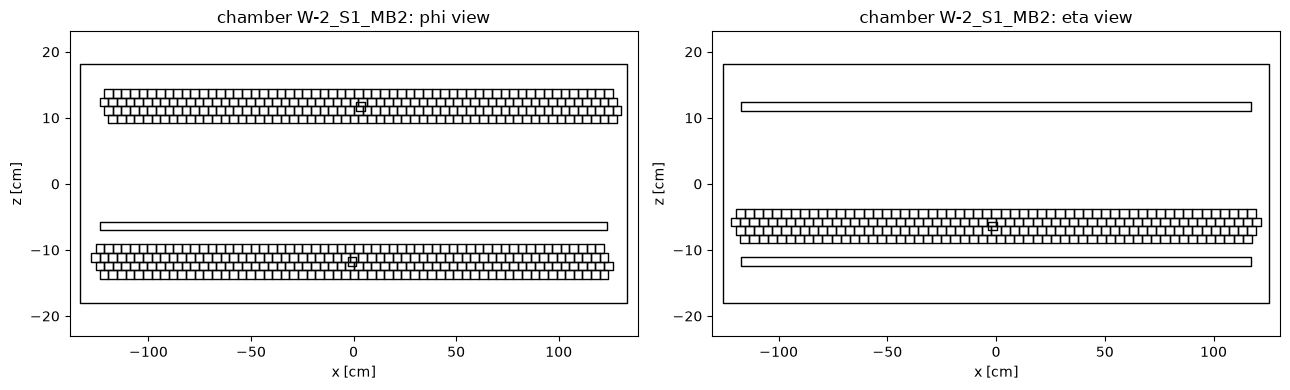

In [6]:
import matplotlib.pyplot as plt
from mpldts.patches import DTStationPatch

width, height, length = station.bounds
x, y, z = station.local_center

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, faceview in zip(axes, ("phi", "eta")):
    DTStationPatch(station, axis, faceview=faceview, local=True)
    if faceview == "phi":
        axis.set_xlim(x - width / 2 - 5, x + width / 2 + 5)
    else:
        axis.set_xlim(y - length / 2 - 5, y + length / 2 + 5)
    axis.set_ylim(z - height / 2 - 5, z + height / 2 + 5)
    axis.set_title("chamber %s: %s view" % (station.name, faceview))
    axis.set_xlabel("x [cm]")
    axis.set_ylabel("z [cm]")
figure.tight_layout()

## Frames: moving a point between reference frames

Every node has a slash-separated `frame_id` and one parent-relative pose. The
`transformer` resolves a path in one call - here from a cell to CMS coordinates.

In [7]:
view_cell = station.super_layer(1).layer(1).cell(1)
print(view_cell.transformer.node.frame_id)
print("cell -> CMS:", [round(float(v), 3) for v in
                        view_cell.transformer.transform((0, 0, 0), "Cell", "CMS")])
print("cell -> Station:", [round(float(v), 3) for v in
                            view_cell.transformer.transform((0, 0, 0), "Cell", "Station")])

/W-2_S1_MB2/SL1/L1/C1
cell -> CMS: [498.775, -140.88, -533.35]
cell -> Station: [-119.45, 0.0, 13.7]


## What changed against 2.x

| 2.x | 3.0 |
|---|---|
| `DTGeometry('DTGeometry.xml')` | `CMSXMLSource()` and `Station.from_spec(source.station(w, se, st))` |
| `DTGEOMETRY` module-level instance | there is no cache: build the view you need |
| `StationsCache` | the spec is the cache; a view build is cheap |
| XML-backed station, super layer, layer, cell | specs, nodes and views |
| `TransformManager` | `FrameGraph`, reached through `station.transformer` |

Next: [2. per-event data](02-event-data.ipynb) shows how an event is drawn
without touching any of this, and [3. your own detector](03-own-detector.ipynb)
builds one that is not in the CMS file.